# 01 — Hakaluki Haor preliminary flood, climate and methane calculations

Runs the **2022 pilot** first, exports exploratory water rasters to Google Drive, and can scale to 2019–2025 in year-level batches. This is actual Earth Engine processing when executed on your account; no result is pre-populated.

**Strict terminology:** Sentinel-1 low-backscatter masks are *screening-grade open-water proxies*, not validated inundated-vegetation maps. TROPOMI supplies *atmospheric column XCH₄*, not wetland flux. Monthly maps cannot resolve true daily flash-flood onset without additional temporal evidence.

In [1]:
from pathlib import Path
import json, sys, hashlib
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path(r"F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project")
sys.path.insert(0,str(ROOT))
from src.hakaluki_core import project_paths,load_boundary,monthly_periods
from src.ee_pipeline import (initialize,geometry_from_geodataframe,choose_s1_geometry,
    run_months,s1_month_water,start_drive_geotiff_export,CH4_BAND,CH4_ID,
    dynamic_world_month,optical_s2_month,chirps_daily_time_series)
import ee
P=project_paths(ROOT)
CFG=json.loads((ROOT/'config/settings.json').read_text())
verified=P['boundary']/'hakaluki_verified.geojson'
candidate=P['boundary']/'hakaluki_analysis_candidate.geojson'
assert verified.exists() or candidate.exists(), 'First run notebook 00.'
boundary_file=verified if verified.exists() else candidate
GDF=load_boundary(boundary_file)
# Fingerprint prevents accidentally combining months computed with different inputs.
fingerprint_bytes=(boundary_file.read_bytes()
     + json.dumps(CFG,sort_keys=True).encode('utf-8')
     + (ROOT/'src'/'ee_pipeline.py').read_bytes()
     + (ROOT/'src'/'hakaluki_core.py').read_bytes())
CACHE_FINGERPRINT=hashlib.sha256(fingerprint_bytes).hexdigest()[:20]
print('Input/code fingerprint:',CACHE_FINGERPRINT)
initialize(CFG['earth_engine_cloud_project'])
ROI=geometry_from_geodataframe(GDF)
CH4_REGION=ROI.buffer(CFG['ch4_buffer_m'])
# Exclusion of central footprint. Exploratory reference ONLY; wind-matched backgrounds need transport analysis.
CH4_BACKGROUND=ROI.buffer(CFG['ch4_reference_outer_m']).difference(
    ROI.buffer(CFG['ch4_reference_inner_m']))
print('Wetland ROI is a geometry; methane target region is buffered by',CFG['ch4_buffer_m'],'m')

Input/code fingerprint: 11d6b74f88543283fc05


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Wetland ROI is a geometry; methane target region is buffered by 30000 m


## A. Choose consistent Sentinel-1 geometry

Same-direction passes and consistent relative orbit reduce incidence-angle artefacts, but may leave months with no image. Record the selected pass/orbit and do not silently substitute a different orbit for missing months.

In [2]:
GEOM=choose_s1_geometry(ROI,CFG['pilot_year'])
print(json.dumps(GEOM,indent=2))
(P['tables']/'sar_acquisition_selection.json').write_text(json.dumps(GEOM,indent=2))
PASS,ORBIT=GEOM['orbit_pass'],GEOM['relative_orbit']

{
  "orbit_pass": "ASCENDING",
  "relative_orbit": 41,
  "pass_counts": {
    "ASCENDING": 29,
    "DESCENDING": 28
  },
  "orbit_counts": {
    "41.0": 29
  }
}


## B. Pilot monthly processing (2022)

For each month, the pipeline returns preliminary Sentinel-1 water area, an Otsu threshold sensitivity range (±1.5 dB is **not** a statistical confidence interval), monthly CHIRPS precipitation, ERA5-Land air temperature, TROPOMI XCH₄, and availability diagnostics.

Processing may fail in months with no SAR pixels or an unsuitable histogram: this is an important QC result and should be logged. Each successful month is saved to a checkpoint CSV, so reruns do not repeat it.

In [3]:
YEAR=CFG['pilot_year']
pilot=run_months(YEAR,YEAR,ROI,CH4_REGION,CH4_BACKGROUND,PASS,ORBIT,P['processed'],cache_fingerprint=CACHE_FINGERPRINT)
display(pilot[['period','s1_scenes','water_area_km2','rain_chirps_mm',
               'ch4_xch4_ppb_roi','ch4_l3_grid_coverage_fraction']])
pilot.to_csv(P['tables']/f'hakaluki_pilot_{YEAR}_monthly.csv',index=False)

Reused 2022-01
Reused 2022-02
Reused 2022-03
Reused 2022-04
Reused 2022-05
Reused 2022-06
Reused 2022-07
Reused 2022-08
Reused 2022-09
Reused 2022-10
Reused 2022-11
Reused 2022-12


,period,s1_scenes,water_area_km2,rain_chirps_mm,ch4_xch4_ppb_roi,ch4_l3_grid_coverage_fraction
0,2022-01,2,30.974967,14.297880,1920.702176,0.914286
1,2022-02,3,19.427697,28.908824,1931.111659,0.933333
2,2022-03,2,15.933807,76.497590,1948.665894,0.923810
3,2022-04,3,32.503457,192.292938,1919.632533,0.876190
4,2022-05,2,64.578758,579.065518,1936.959899,0.333333
5,2022-06,3,164.507911,1041.347547,NaN,0.000000
6,2022-07,1,160.216957,494.037639,1935.374624,0.019048
7,2022-08,3,159.116286,339.215527,NaN,0.000000
8,2022-09,2,150.535366,477.426790,1996.044284,0.838095
9,2022-10,3,130.227960,312.637406,1956.016563,1.000000


## C. Generate graphs from real outputs

No gaps are interpolated. Area estimates and methane levels are not placed on a shared axis to imply causality.

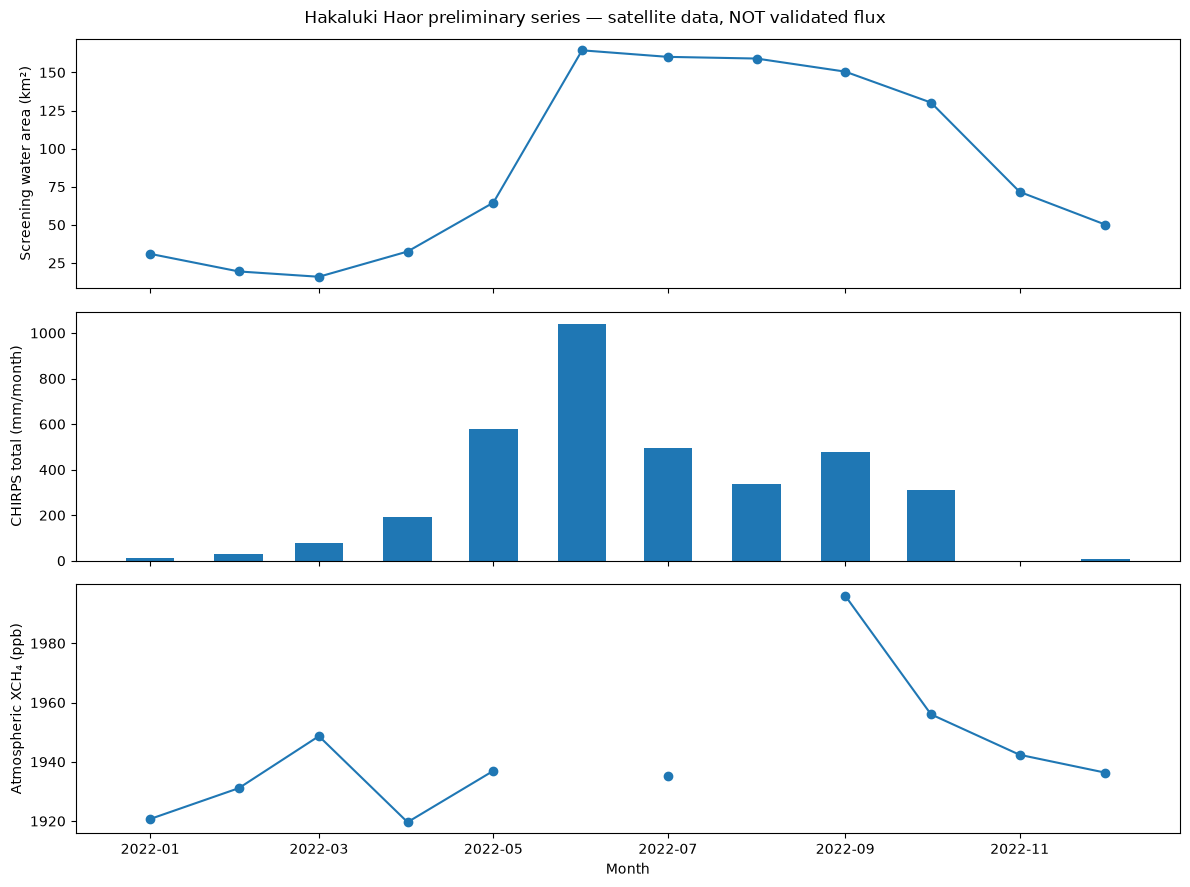

In [4]:
pilot['period_date']=pd.to_datetime(pilot['period']+'-01')
fig,axes=plt.subplots(3,1,figsize=(12,9),sharex=True)
axes[0].plot(pilot['period_date'],pilot['water_area_km2'],'o-')
axes[0].set_ylabel('Screening water area (km²)')
axes[1].bar(pilot['period_date'],pilot['rain_chirps_mm'],width=17)
axes[1].set_ylabel('CHIRPS total (mm/month)')
axes[2].plot(pilot['period_date'],pilot['ch4_xch4_ppb_roi'],'o-')
axes[2].set_ylabel('Atmospheric XCH₄ (ppb)')
axes[2].set_xlabel('Month')
fig.suptitle('Hakaluki Haor preliminary series — satellite data, NOT validated flux')
fig.tight_layout()
fig.savefig(P['figures']/f'hakaluki_{YEAR}_pilot_series.png',dpi=180)
plt.show()

## C2. Rainfall pulse screening using daily observations

This uses daily CHIRPS for 2022. A large local rainfall pulse is **not proof** of a flash flood (many haor floods are influenced by upstream catchments). Use water-level observations for hydrological event definition when available. The preliminary 3-day rolling rainfall maximum flags candidate periods only.

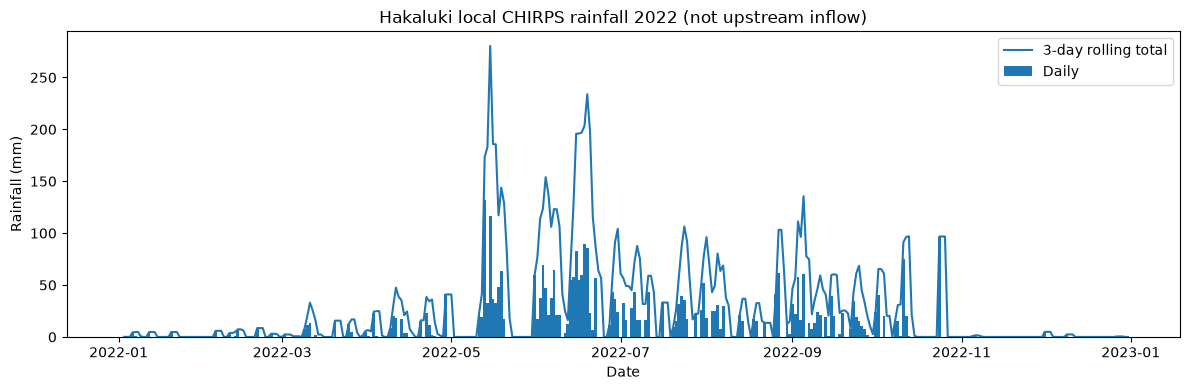

In [5]:
from src.ee_pipeline import chirps_daily_time_series
RAIN_DAILY=chirps_daily_time_series(ROI,f'{YEAR}-01-01',f'{YEAR+1}-01-01')
RAIN_DAILY['rolling_3day_mm']=RAIN_DAILY['rain_chirps_mm_day'].rolling(3,min_periods=3).sum()
RAIN_DAILY.to_csv(P['processed']/f'CHIRPS_daily_{YEAR}.csv',index=False)
fig,ax=plt.subplots(figsize=(12,4))
ax.bar(RAIN_DAILY['date'],RAIN_DAILY['rain_chirps_mm_day'],width=1.0,label='Daily')
ax.plot(RAIN_DAILY['date'],RAIN_DAILY['rolling_3day_mm'],label='3-day rolling total')
ax.set(title=f'Hakaluki local CHIRPS rainfall {YEAR} (not upstream inflow)',ylabel='Rainfall (mm)',xlabel='Date')
ax.legend();fig.tight_layout()
fig.savefig(P['figures']/f'CHIRPS_daily_{YEAR}.png',dpi=170)
plt.show()

## D. Interactive satellite layers for selected months

These layers are illustrative classification outputs. Use independent optical imagery and manually interpreted stratified validation points to produce a defensible accuracy assessment. Flooded vegetation is not reliably captured by VV thresholding alone.

In [6]:
import geemap
PRE,WPRE=s1_month_water(ROI,'2022-03-01','2022-04-01',PASS,ORBIT)
POST,WPOST=s1_month_water(ROI,'2022-06-01','2022-07-01',PASS,ORBIT)
print('March SAR summary:',WPRE)
print('June SAR summary:',WPOST)
M=geemap.Map()
M.centerObject(ROI,11)
M.addLayer(ROI,{'color':'ff6600'},'Boundary under review')
HAB,HSTATS=dynamic_world_month(ROI,'2022-06-01','2022-07-01')
if HAB is not None: M.addLayer(HAB,{ 'min':0,'max':8,'palette':['#419BDF','#397D49','#88B053','#7A87C6','#E49635','#DFC35A','#C4281B','#A59B8F','#B39FE1'] },'DW June modal habitat – cloud limited',False)
print('Dynamic World habitat screen:',HSTATS)
if PRE is not None: M.addLayer(PRE.selfMask(),{'palette':['#54a0ff']},'March 2022 preliminary water')
if POST is not None: M.addLayer(POST.selfMask(),{'palette':['#062cff']},'June 2022 preliminary water')
M

March SAR summary: {'s1_scenes': 2, 'water_threshold_db': -15.188828333044754, 'water_area_km2': 15.933806810296513, 'water_area_low_km2': 11.200474794672708, 'water_area_high_km2': 32.13746282942948, 'sar_valid_area_km2': 172.38527291362234, 'sar_qc_status': 'screening_only_unvalidated'}
June SAR summary: {'s1_scenes': 3, 'water_threshold_db': -15.20579678213733, 'water_area_km2': 164.50791135486514, 'water_area_low_km2': 162.72487291679616, 'water_area_high_km2': 165.7582861376075, 'sar_valid_area_km2': 172.38527291362234, 'sar_qc_status': 'screening_only_unvalidated'}
Dynamic World habitat screen: {'dw_scene_count': 1, 'dw_water_km2': 26.460555104861513, 'dw_flooded_vegetation_km2': 0.09177659442186542, 'dw_crops_km2': 0.006406390018717447, 'dw_valid_class_area_km2': 26.384677157621482}


Map(center=[24.659190685953774, 92.05303257798614], controls=(WidgetControl(options=['position', 'transparent_…

## Event-scale rainfall precursor screen (2022)

Daily CHIRPS precipitation provides an additional event context (not a precise upstream discharge model). Plot 3-day and 7-day totals to identify rainfall pulse candidates; actual flood onset still requires SAR and/or gauge time series.

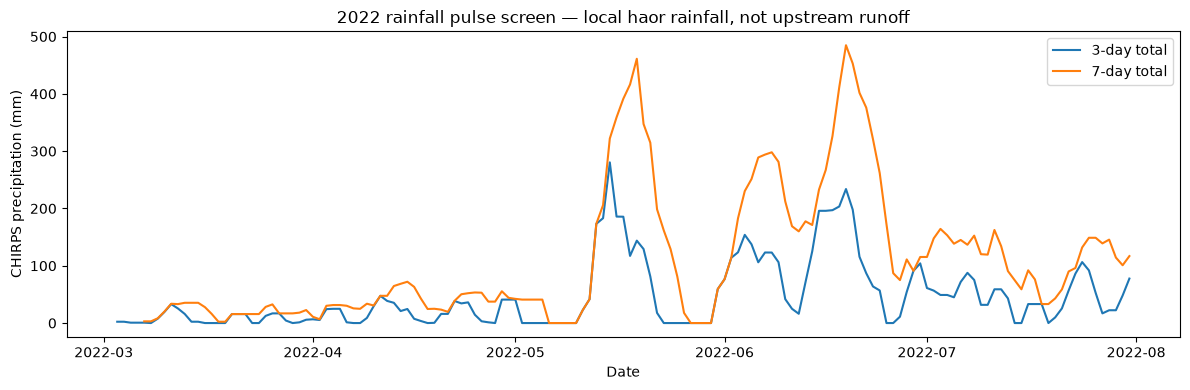

In [7]:
rain_daily=chirps_daily_time_series(ROI,'2022-03-01','2022-08-01')
rain_daily['rain_3day_mm']=rain_daily['rain_chirps_mm_day'].rolling(3,min_periods=3).sum()
rain_daily['rain_7day_mm']=rain_daily['rain_chirps_mm_day'].rolling(7,min_periods=7).sum()
rain_daily.to_csv(P['tables']/'hakaluki_2022_daily_CHIRPS_rainfall.csv',index=False)
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(rain_daily['date'],rain_daily['rain_3day_mm'],label='3-day total')
ax.plot(rain_daily['date'],rain_daily['rain_7day_mm'],label='7-day total')
ax.legend();ax.set(ylabel='CHIRPS precipitation (mm)',xlabel='Date',
                   title='2022 rainfall pulse screen — local haor rainfall, not upstream runoff')
fig.tight_layout();fig.savefig(P['figures']/'2022_rainfall_pulses.png',dpi=170);plt.show()

## E. Export georeferenced rasters to Google Drive

GeoTIFF tasks are asynchronous **within Earth Engine**. The notebook starts the task and prints its status; it does not imply that output has been downloaded. The reference `image` pixels are 1 where selected as water and masked elsewhere. Task completion and downloadable file presence must be verified in the GEE Tasks panel or via `task.status()`.

In [8]:
EXPORT_MONTHS=['2022-03','2022-04','2022-06','2022-07']
# Deliberately opt in: to avoid accidentally submitting tasks on every run.
SUBMIT_DRIVE_EXPORTS=False
export_tasks=[]
if SUBMIT_DRIVE_EXPORTS:
    for ym in EXPORT_MONTHS:
        period=pd.Period(ym, freq='M')
        start=period.start_time.strftime('%Y-%m-%d')
        end=(period+1).start_time.strftime('%Y-%m-%d')
        water,metrics=s1_month_water(ROI,start,end,PASS,ORBIT)
        if water is None:
            print('Missing SAR month:',ym); continue
        desc='HAKALUKI_screening_water_'+ym.replace('-','_')
        task=start_drive_geotiff_export(water.clip(ROI),ROI,desc,scale=30)
        export_tasks.append(task)
        print(desc,task.status())
else:
    print('Set SUBMIT_DRIVE_EXPORTS=True after examining the preliminary maps.')

Set SUBMIT_DRIVE_EXPORTS=True after examining the preliminary maps.


## E2. Per-pixel 2022 **observed-month frequency** map

This map represents the *fraction of months with available, same-orbit SAR composites classified as low-backscatter water.* It is **not** flood duration or a daily hydroperiod, and it is sensitive to the SAR classification threshold. Valid observation count is saved alongside it. Optional Google Drive exports require opt-in.

In [9]:
# Computing the twelve masks requires repeat Earth Engine queries. No map values are invented.
RUN_FREQUENCY_MAP=False
EXPORT_FREQUENCY_MAP=False
if RUN_FREQUENCY_MAP:
    water_stack=[]
    for mm in range(1,13):
        pp=pd.Period(f'{YEAR}-{mm:02d}',freq='M')
        im,meta=s1_month_water(ROI,pp.start_time.strftime('%Y-%m-%d'),
             (pp+1).start_time.strftime('%Y-%m-%d'),PASS,ORBIT)
        if im is not None:
            water_stack.append(im.rename('water'))
    if not water_stack:
        raise RuntimeError('No water-screening masks were generated.')
    samples=ee.ImageCollection.fromImages(water_stack)
    valid_months=samples.count().rename('valid_months')
    observed_water_months=samples.sum().rename('water_months')
    observed_freq=observed_water_months.divide(valid_months).updateMask(valid_months.gt(0)).rename('observed_fraction')
    FREQMAP=geemap.Map();FREQMAP.centerObject(ROI,11)
    FREQMAP.addLayer(observed_freq,{'min':0,'max':1,'palette':['#fff7bc','#41b6c4','#253494']},
                     '2022 screened-water fraction of observed months')
    FREQMAP.addLayer(ROI,{'color':'#df5f2b'},'Candidate boundary')
    display(FREQMAP)
    if EXPORT_FREQUENCY_MAP:
        t1=start_drive_geotiff_export(observed_freq,ROI,f'HAKALUKI_{YEAR}_water_screen_fraction',scale=30,as_byte=False)
        t2=start_drive_geotiff_export(valid_months,ROI,f'HAKALUKI_{YEAR}_valid_SAR_months',scale=30)
        print('Submitted GEE export tasks:',t1.status(),t2.status())
else:
    print('Set RUN_FREQUENCY_MAP=True to compute the observed-month frequency.')

Set RUN_FREQUENCY_MAP=True to compute the observed-month frequency.


## F. Scale to 2019–2025 after passing feasibility checks

**Run one year at a time**, first checking monthly SAR coverage and CH₄ missingness. With only about 84 monthly observations in seven years, machine learning is an exploratory benchmark, not sufficient evidence for fine-scale flux attribution.

In [10]:
RUN_FULL_RECORD=True
if RUN_FULL_RECORD:
    for y in range(CFG['start_year'],CFG['end_year']+1):
        print('Year',y)
        run_months(y,y,ROI,CH4_REGION,CH4_BACKGROUND,PASS,ORBIT,P['processed'],cache_fingerprint=CACHE_FINGERPRINT)
else:
    print('Pilot complete if Stage B executed; full record not launched.')

Year 2019
Reused 2019-01
Reused 2019-02
Reused 2019-03
Reused 2019-04
Reused 2019-05
Reused 2019-06
Reused 2019-07
Reused 2019-08
Reused 2019-09
Reused 2019-10
Reused 2019-11
Reused 2019-12
Year 2020
Reused 2020-01
Reused 2020-02
Reused 2020-03
Reused 2020-04
Reused 2020-05
Reused 2020-06
Reused 2020-07
Reused 2020-08
Reused 2020-09
Reused 2020-10
Reused 2020-11
Reused 2020-12
Year 2021
Reused 2021-01
Reused 2021-02
Reused 2021-03
Reused 2021-04
Reused 2021-05
Reused 2021-06
Calculating 2021-07...
Calculating 2021-08...
Calculating 2021-09...
Calculating 2021-10...
Calculating 2021-11...
Calculating 2021-12...
Year 2022
Reused 2022-01
Reused 2022-02
Reused 2022-03
Reused 2022-04
Reused 2022-05
Reused 2022-06
Reused 2022-07
Reused 2022-08
Reused 2022-09
Reused 2022-10
Reused 2022-11
Reused 2022-12
Year 2023
Calculating 2023-01...
Calculating 2023-02...
Calculating 2023-03...
Calculating 2023-04...
Calculating 2023-05...
Calculating 2023-06...
Calculating 2023-07...
Calculating 2023-08..

## Remaining requirements before publications

1. Verify candidate wetland boundary against a traceable authoritative map.
2. Compare VV-screening flood masks with independently interpreted reference samples and a more advanced flooded-vegetation-aware classifier.
3. Add event-scale 1–3-day hydrological records if available; monthly SAR composites do **not** resolve flood onset accurately.
4. Record missingness and quality of TROPOMI observations; monthly regional XCH₄ is not local CH₄ flux.
5. When available, incorporate field chamber/flux observations using `results/calibration/field_flux_template.csv`.

In [11]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(
    r"F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project"
)

processed = ROOT / "data" / "processed"
figures = ROOT / "results" / "figures"
tables = ROOT / "results" / "tables"

figures.mkdir(parents=True, exist_ok=True)
tables.mkdir(parents=True, exist_ok=True)

# Read the actual 2022 results
csv_path = processed / "monthly_2022_2022_combined.csv"

if csv_path.exists():
    df = pd.read_csv(csv_path)
else:
    files = sorted(processed.glob("monthly_2022-??.csv"))
    if not files:
        raise FileNotFoundError("No 2022 monthly CSV files found.")
    df = pd.concat(
        [pd.read_csv(f) for f in files],
        ignore_index=True
    )

df = df.sort_values("period").reset_index(drop=True)

# Geometry-derived study area from Notebook 00
STUDY_AREA_KM2 = 172.2907

df["water_percent_roi"] = (
    df["water_area_km2"] / STUDY_AREA_KM2 * 100
)

# Exploratory coverage threshold, not a validated
# satellite retrieval quality threshold
df["ch4_coverage_flag"] = df[
    "ch4_l3_grid_coverage_fraction"
].apply(
    lambda x: "Insufficient for screening"
    if pd.isna(x) or x < 0.5
    else "Requires additional QA"
)

df.to_csv(
    tables / "hakaluki_2022_pilot_quality_audit.csv",
    index=False
)

# Figure 1: preliminary surface-water area
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(df["period"], df["water_area_km2"], marker="o")
ax.set(
    title="Hakaluki Haor: Preliminary Water Area (2022)",
    xlabel="Month",
    ylabel="Classified water area (km²)"
)
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(
    figures / "hakaluki_2022_water_area.png",
    dpi=300, bbox_inches="tight"
)
plt.close(fig)

# Figure 2: monthly precipitation
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(df["period"], df["rain_chirps_mm"])
ax.set(
    title="Hakaluki Haor: CHIRPS Rainfall (2022)",
    xlabel="Month",
    ylabel="Monthly precipitation (mm)"
)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(
    figures / "hakaluki_2022_rainfall.png",
    dpi=300, bbox_inches="tight"
)
plt.close(fig)

# Figure 3: gridded methane coverage
fig, ax = plt.subplots(figsize=(11, 5))
coverage = df["ch4_l3_grid_coverage_fraction"] * 100
ax.bar(df["period"], coverage)
ax.set(
    title="TROPOMI Methane: Monthly Gridded Data Coverage",
    xlabel="Month",
    ylabel="L3 grid coverage (%)",
    ylim=(0, 100)
)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(
    figures / "hakaluki_2022_methane_coverage.png",
    dpi=300, bbox_inches="tight"
)
plt.close(fig)

print("Export completed.")
print("Quality audit:", tables)
print("Figures:", figures)
display(df[[
    "period",
    "water_area_km2",
    "water_percent_roi",
    "rain_chirps_mm",
    "ch4_xch4_ppb_roi",
    "ch4_coverage_flag"
]])


Export completed.
Quality audit: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\results\tables
Figures: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\results\figures


,period,water_area_km2,water_percent_roi,rain_chirps_mm,ch4_xch4_ppb_roi,ch4_coverage_flag
0,2022-01,30.974967,17.978316,14.297880,1920.702176,Requires additional QA
1,2022-02,19.427697,11.276115,28.908824,1931.111659,Requires additional QA
2,2022-03,15.933807,9.248211,76.497590,1948.665894,Requires additional QA
3,2022-04,32.503457,18.865474,192.292938,1919.632533,Requires additional QA
4,2022-05,64.578758,37.482440,579.065518,1936.959899,Insufficient for screening
5,2022-06,164.507911,95.482758,1041.347547,NaN,Insufficient for screening
6,2022-07,160.216957,92.992226,494.037639,1935.374624,Insufficient for screening
7,2022-08,159.116286,92.353380,339.215527,NaN,Insufficient for screening
8,2022-09,150.535366,87.372891,477.426790,1996.044284,Requires additional QA
9,2022-10,130.227960,75.586181,312.637406,1956.016563,Requires additional QA


In [12]:

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path(
    r"F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project"
)

DATA = ROOT / "data" / "processed"
TABLES = ROOT / "results" / "tables"

TABLES.mkdir(parents=True, exist_ok=True)

# Expected months: January 2019 to December 2025
expected = pd.period_range(
    "2019-01", "2025-12", freq="M"
).astype(str).tolist()

# Check every monthly checkpoint
missing_files = [
    month for month in expected
    if not (DATA / f"monthly_{month}.csv").exists()
]

print("Expected months:", len(expected))
print("Monthly files found:", len(expected) - len(missing_files))
print("Missing months:", missing_files)

if missing_files:
    raise RuntimeError(
        "Some monthly files are missing. "
        "Complete processing before continuing."
    )

# Load all checkpoints
frames = [
    pd.read_csv(DATA / f"monthly_{month}.csv")
    for month in expected
]

df = pd.concat(frames, ignore_index=True)
df = df.sort_values("period").reset_index(drop=True)

# Verify uniqueness and chronological completeness
if df["period"].duplicated().any():
    raise ValueError("Duplicate monthly records detected.")

if set(df["period"]) != set(expected):
    raise ValueError("Monthly periods do not match 2019-2025.")

if len(df) != 84:
    raise ValueError("Expected exactly 84 monthly records.")

# Save consolidated research dataset
output = DATA / "hakaluki_monthly_2019_2025.csv"
df.to_csv(output, index=False)

print("\nFULL DATASET CHECK PASSED")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Saved to:", output)

# Inspect missing values in important variables
important_columns = [
    "water_area_km2",
    "rain_chirps_mm",
    "temp2m_era5_c",
    "ch4_xch4_ppb_roi",
    "ch4_l3_grid_coverage_fraction",
    "ndvi_s2_mean",
    "mndwi_s2_mean"
]

available = [c for c in important_columns if c in df.columns]

quality = pd.DataFrame({
    "variable": available,
    "valid_months": [df[c].notna().sum() for c in available],
    "missing_months": [df[c].isna().sum() for c in available],
    "missing_percent": [
        round(df[c].isna().mean() * 100, 2)
        for c in available
    ]
})

quality.to_csv(
    TABLES / "hakaluki_2019_2025_data_quality.csv",
    index=False
)

display(quality)

print("\nFirst three records:")
display(df.head(3))

print("\nLast three records:")
display(df.tail(3))


Expected months: 84
Monthly files found: 84
Missing months: []

FULL DATASET CHECK PASSED
Rows: 84
Columns: 30
Saved to: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\data\processed\hakaluki_monthly_2019_2025.csv


,variable,valid_months,missing_months,missing_percent
0,water_area_km2,84,0,0.00
1,rain_chirps_mm,84,0,0.00
2,temp2m_era5_c,84,0,0.00
3,ch4_xch4_ppb_roi,69,15,17.86
4,ch4_l3_grid_coverage_fraction,84,0,0.00
5,ndvi_s2_mean,84,0,0.00
6,mndwi_s2_mean,84,0,0.00



First three records:


,year,month,period,start,end,s1_scenes,water_threshold_db,water_area_km2,water_area_low_km2,water_area_high_km2,...,dw_scene_count,dw_water_km2,dw_flooded_vegetation_km2,dw_crops_km2,dw_valid_class_area_km2,s2_scene_count,ndvi_s2_mean,mndwi_s2_mean,result_status,cache_fingerprint
0,2019,1,2019-01,2019-01-01,2019-02-01,3,-16.793149,38.424266,34.183032,46.000658,...,22,51.797364,63.060943,28.775363,172.385273,24,0.286941,0.034206,preliminary_unvalidated,11d6b74f88543283fc05
1,2019,2,2019-02,2019-02-01,2019-03-01,2,-16.398057,30.118934,28.321768,33.361474,...,17,42.389237,28.132879,41.364400,172.385273,24,0.423449,-0.150030,preliminary_unvalidated,11d6b74f88543283fc05
2,2019,3,2019-03,2019-03-01,2019-04-01,3,-16.000991,32.538421,30.143240,37.309936,...,19,44.177634,9.408739,58.849916,172.385273,25,0.455000,-0.188747,preliminary_unvalidated,11d6b74f88543283fc05



Last three records:


,year,month,period,start,end,s1_scenes,water_threshold_db,water_area_km2,water_area_low_km2,water_area_high_km2,...,dw_scene_count,dw_water_km2,dw_flooded_vegetation_km2,dw_crops_km2,dw_valid_class_area_km2,s2_scene_count,ndvi_s2_mean,mndwi_s2_mean,result_status,cache_fingerprint
81,2025,10,2025-10,2025-10-01,2025-11-01,2,-16.000984,133.163966,125.347234,140.041714,...,20,143.928095,13.482011,8.611522,172.385273,29,-0.191371,0.571239,preliminary_unvalidated,11d6b74f88543283fc05
82,2025,11,2025-11,2025-11-01,2025-12-01,3,-15.599515,80.579518,69.073784,93.745787,...,25,90.965846,55.647235,13.432358,172.385273,29,0.074656,0.210514,preliminary_unvalidated,11d6b74f88543283fc05
83,2025,12,2025-12,2025-12-01,2026-01-01,2,-16.398557,47.829208,40.106644,59.066668,...,22,60.874006,64.140270,32.202078,172.385273,32,0.234930,0.047738,preliminary_unvalidated,11d6b74f88543283fc05
